# Rossmann Sales Forecasting

**Goal:** Explore customer purchasing behaviour, predict daily store sales up to **6 weeks ahead**, compare Machine Learning and LSTM, serialize models, and prepare the project for web deployment.

The notebook follows the original project brief. Charts are placed directly after the analysis they explain, and the code is intentionally simple and interview-friendly.

## 1. Project Requirements Covered

- Data cleaning and reusable preprocessing
- Promotion distribution in train and test
- Holiday behaviour and seasonality
- Sales vs customers correlation
- Promotion impact and store targeting
- Open/closed store behaviour
- Weekday and weekend behaviour
- Assortment and competition analysis
- Date-based feature engineering
- Stationarity, differencing, ACF and PACF for the time series
- Scikit-learn preprocessing pipeline and Random Forest regression
- Loss function and evaluation
- Feature importance and prediction analysis
- Prediction interval estimate
- Timestamped model serialization
- Two-layer LSTM
- MLflow experiment example
- 42-day / 6-week forecast
- Predicted sales and customer numbers
- CSV output for the web app

## 2. Import Libraries

In [ ]:
import os
import logging
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.stattools import adfuller, acf, pacf

warnings.filterwarnings("ignore")

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger("rossmann")

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 3. Load the Rossmann Data

In [ ]:
train = pd.read_csv("/train.csv")
test = pd.read_csv("/test.csv")
store = pd.read_csv("/store.csv")

train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])

print("Train:", train.shape)
print("Test:", test.shape)
print("Store:", store.shape)
display(train.head())

Train: (1017209, 9)
Test: (41088, 8)
Store: (1115, 10)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


## 4. Basic Data Understanding

In [ ]:
display(train.info())
display(train.describe())
print("Duplicate rows:", train.duplicated().sum())
print("Train date range:", train["Date"].min().date(), "to", train["Date"].max().date())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[ns]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[ns](1), int64(7), object(1)
memory usage: 69.8+ MB


None

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1017209,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,2014-04-11 01:30:42.846061824,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
min,1.000000e+00,1.000000e+00,2013-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,2013-08-17 00:00:00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,2014-04-02 00:00:00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,2014-12-12 00:00:00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,2015-07-31 00:00:00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00
std,3.219087e+02,1.997391e+00,NaN,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01


Duplicate rows: 0
Train date range: 2013-01-01 to 2015-07-31


## 5. Data Cleaning and Merge Store Information

In [ ]:
train = train.merge(store, on="Store", how="left")
test = test.merge(store, on="Store", how="left")

# CompetitionDistance has missing values because some stores have no known competitor.
median_distance = train["CompetitionDistance"].median()
train["CompetitionDistance"] = train["CompetitionDistance"].fillna(median_distance)
test["CompetitionDistance"] = test["CompetitionDistance"].fillna(median_distance)

# Keep categorical holiday values consistent.
train["StateHoliday"] = train["StateHoliday"].astype(str)
test["StateHoliday"] = test["StateHoliday"].astype(str)

print("Remaining missing values in key columns:")
display(train[["Sales", "Customers", "Open", "Promo", "StoreType", "Assortment", "CompetitionDistance"]].isna().sum())
logger.info("Data cleaning completed")

Remaining missing values in key columns:


,0
Sales,0
Customers,0
Open,0
Promo,0
StoreType,0
Assortment,0
CompetitionDistance,0


## 6. Promotion Distribution: Train vs Test

The brief asks whether promotions are distributed similarly between training and test data.

,Train %,Test %
Promo,,
0,61.848548,60.416667
1,38.151452,39.583333


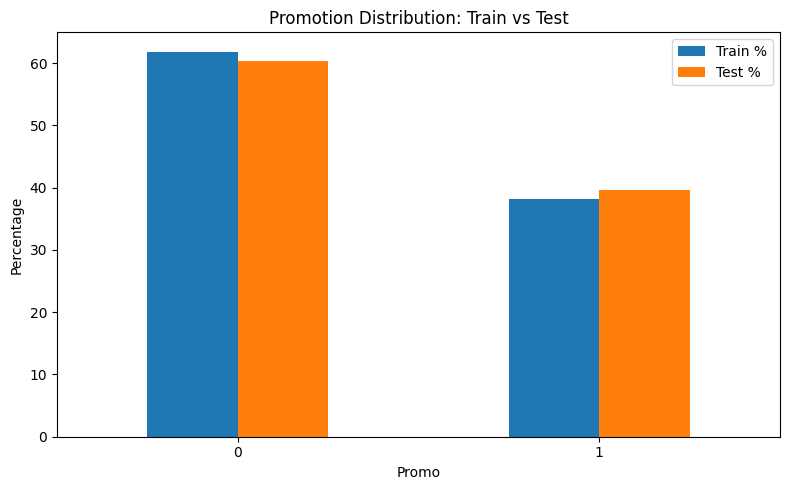

In [ ]:
train_promo = train["Promo"].value_counts(normalize=True).sort_index()
test_promo = test["Promo"].value_counts(normalize=True).sort_index()

promo_compare = pd.DataFrame({"Train %": train_promo * 100, "Test %": test_promo * 100})
display(promo_compare)

promo_compare.plot(kind="bar", figsize=(8, 5))
plt.title("Promotion Distribution: Train vs Test")
plt.xlabel("Promo")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Daily Sales Trend

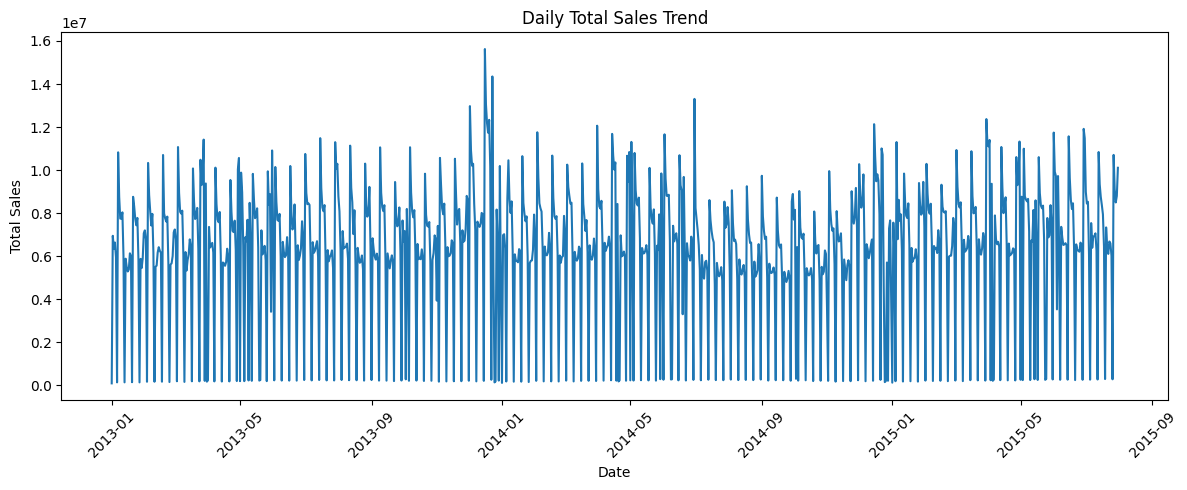

In [ ]:
daily_sales = train.groupby("Date", as_index=False)["Sales"].sum()
plt.figure(figsize=(12, 5))
plt.plot(daily_sales["Date"], daily_sales["Sales"])
plt.title("Daily Total Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Monthly Sales Trend and Seasonality

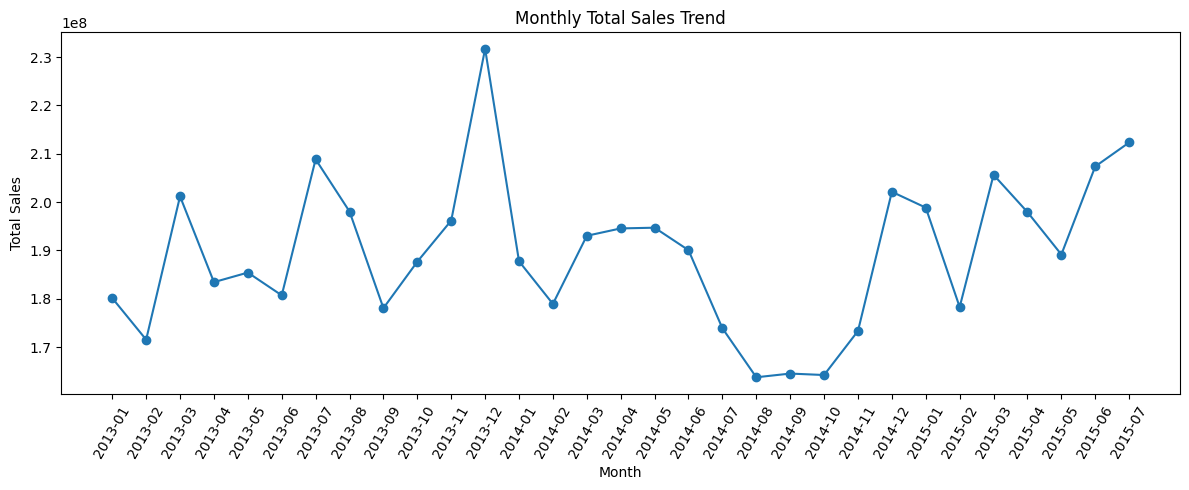

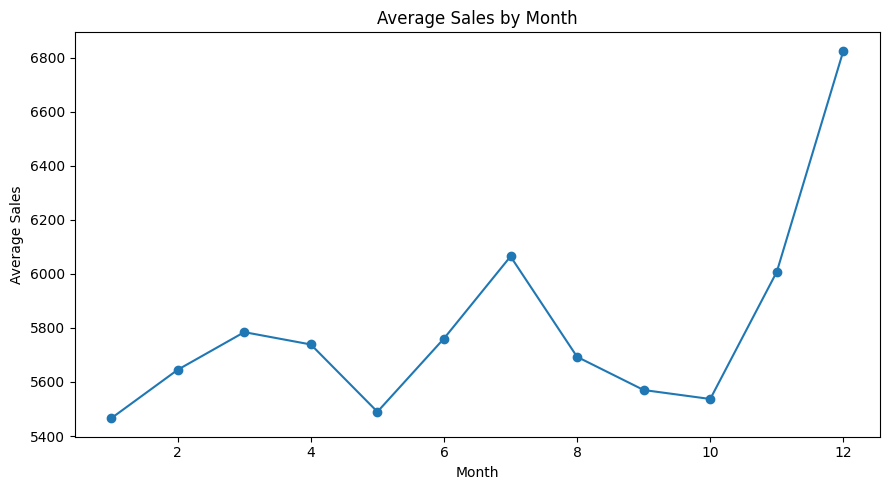

In [ ]:
monthly_sales = train.assign(Month=train["Date"].dt.to_period("M").astype(str)).groupby("Month", as_index=False)["Sales"].sum()
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Month"], monthly_sales["Sales"], marker="o")
plt.title("Monthly Total Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

train["MonthName"] = train["Date"].dt.month_name()
train["Month"] = train["Date"].dt.month  # Added this line to create the 'Month' column
month_order = list(pd.date_range("2020-01-01", periods=12, freq="MS").month_name())
seasonality = train.groupby("Month")["Sales"].mean()
plt.figure(figsize=(9, 5))
plt.plot(seasonality.index, seasonality.values, marker="o")
plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

## 9. Holiday Behaviour: Before, During and After Holidays

,Average Sales
HolidayStatus,
Before Holiday,5632.308308
During Holiday,1563.304216
After Holiday,6874.590616
Normal,5879.653831


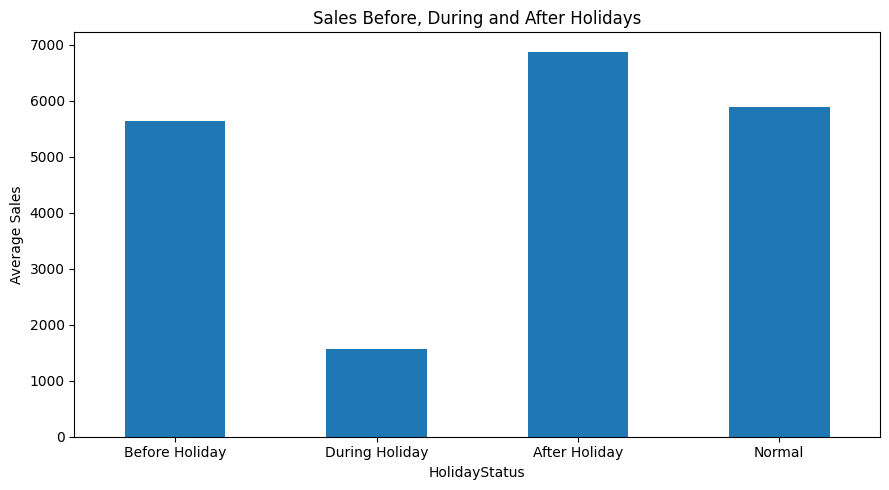

In [ ]:

holiday_dates = train.loc[train["StateHoliday"] != "0", "Date"].drop_duplicates().sort_values()
holiday_set = set(holiday_dates)

train["HolidayStatus"] = "Normal"
train.loc[train["Date"].isin(holiday_set), "HolidayStatus"] = "During Holiday"
train.loc[train["Date"].isin([d - pd.Timedelta(days=1) for d in holiday_dates]), "HolidayStatus"] = "Before Holiday"
train.loc[train["Date"].isin([d + pd.Timedelta(days=1) for d in holiday_dates]), "HolidayStatus"] = "After Holiday"

holiday_summary = train.groupby("HolidayStatus")["Sales"].mean().reindex(["Before Holiday", "During Holiday", "After Holiday", "Normal"])
display(holiday_summary.to_frame("Average Sales"))
holiday_summary.plot(kind="bar", figsize=(9, 5))
plt.title("Sales Before, During and After Holidays")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Christmas and Easter Seasonality

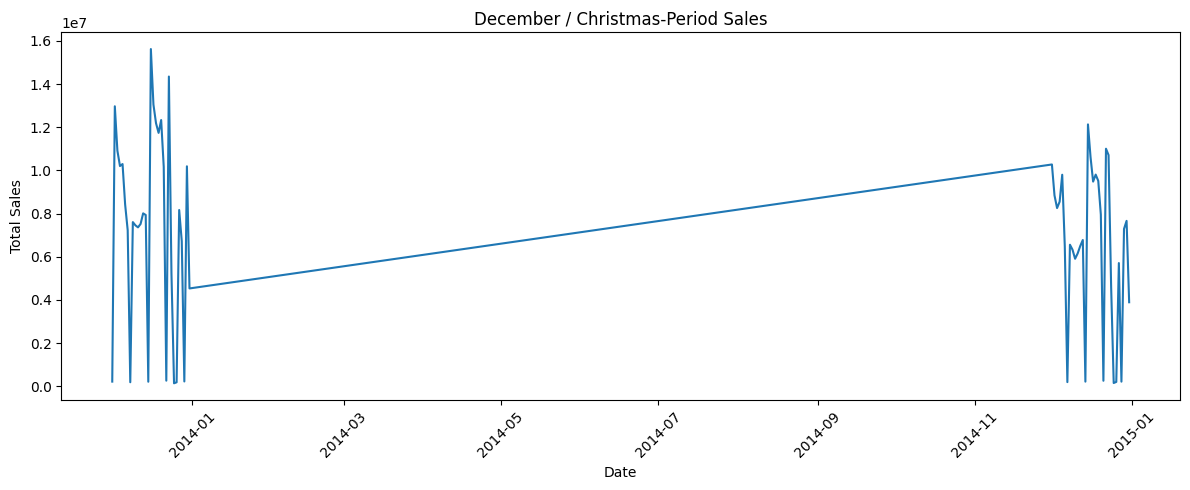

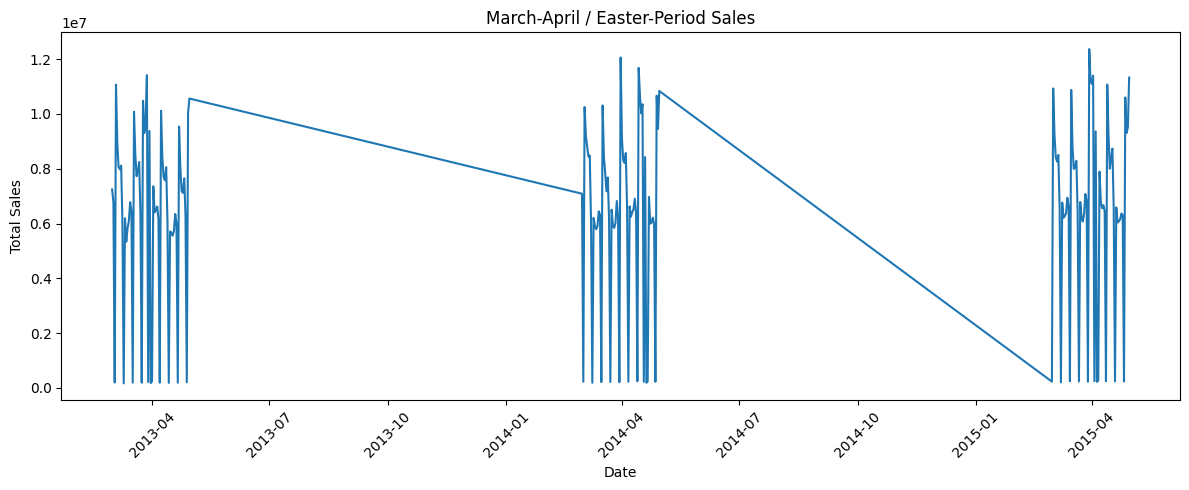

In [ ]:
train["Month"] = train["Date"].dt.month
christmas = train[train["Month"] == 12].groupby("Date")["Sales"].sum()
easter = train[train["Month"].isin([3, 4])].groupby("Date")["Sales"].sum()

plt.figure(figsize=(12, 5))
plt.plot(christmas.index, christmas.values, label="December")
plt.title("December / Christmas-Period Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(easter.index, easter.values)
plt.title("March-April / Easter-Period Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 11. Sales and Customers Correlation

Sales vs Customers correlation: 0.895


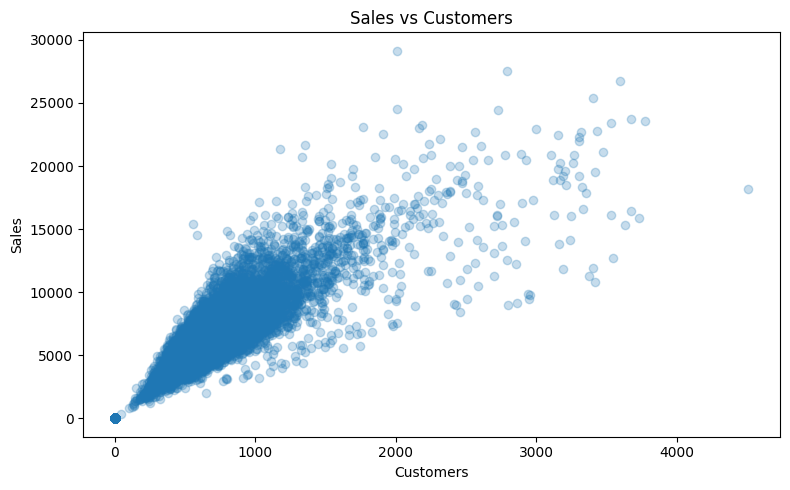

In [ ]:
correlation = train["Sales"].corr(train["Customers"])
print("Sales vs Customers correlation:", round(correlation, 3))

sample = train.sample(min(10000, len(train)), random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(sample["Customers"], sample["Sales"], alpha=0.25)
plt.title("Sales vs Customers")
plt.xlabel("Customers")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## 12. Promotion Impact and Stores Where Promos Perform Best

,Sales,Customers
Promo,,
0,4406.050805,517.823542
1,7991.152046,820.098815


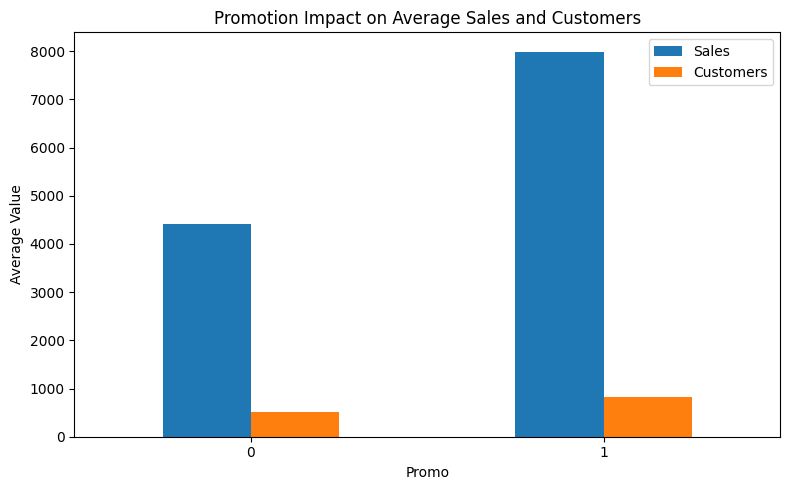

Top 10 stores by promotion sales lift:


,Promo_Sales,NonPromo_Sales,Promo_Lift_%
Store,,,
198,4211.216667,1292.500000,225.819471
607,5435.191667,1880.798969,188.983127
543,3817.008333,1383.443299,175.906381
575,7294.339161,2664.858051,173.723366
271,10507.675000,4009.890034,162.043969
693,8854.822222,3390.144330,161.193075
96,6891.002778,2675.621993,157.547695
1108,7640.116667,2976.214777,156.705824
552,10272.252778,4008.190722,156.281537


In [ ]:
promo_summary = train.groupby("Promo")[["Sales", "Customers"]].mean()
display(promo_summary)

promo_summary.plot(kind="bar", figsize=(8, 5))
plt.title("Promotion Impact on Average Sales and Customers")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

store_promo = train.groupby("Store").agg(
    Promo_Sales=("Sales", lambda x: x[train.loc[x.index, "Promo"] == 1].mean()),
    NonPromo_Sales=("Sales", lambda x: x[train.loc[x.index, "Promo"] == 0].mean())
).dropna()
store_promo["Promo_Lift_%"] = (store_promo["Promo_Sales"] / store_promo["NonPromo_Sales"] - 1) * 100
print("Top 10 stores by promotion sales lift:")
display(store_promo.sort_values("Promo_Lift_%", ascending=False).head(10))

## 13. Open vs Closed Stores and Customer Behaviour

,Sales,Customers
Open,,
0,0.000000,0.000000
1,6955.514291,762.728395


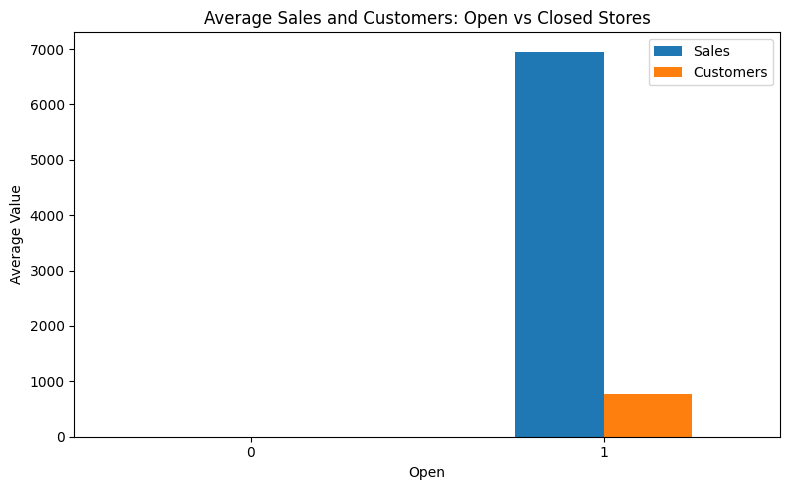

In [ ]:
open_summary = train.groupby("Open")[["Sales", "Customers"]].mean()
display(open_summary)

open_summary.plot(kind="bar", figsize=(8, 5))
plt.title("Average Sales and Customers: Open vs Closed Stores")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 14. Weekday and Weekend Behaviour

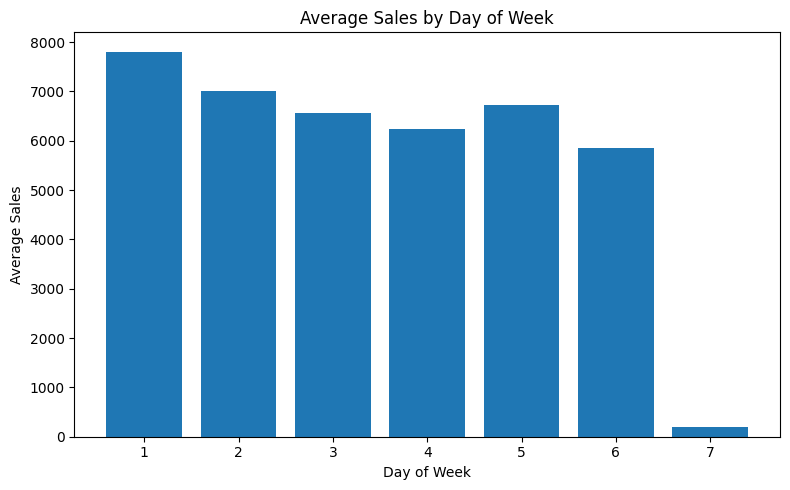

,Average Sales
IsWeekend,
False,6866.806351
True,3025.872894


In [ ]:
train["DayOfWeek"] = train["Date"].dt.dayofweek + 1
train["IsWeekend"] = train["DayOfWeek"].isin([6, 7])

day_sales = train.groupby("DayOfWeek")["Sales"].mean()
plt.figure(figsize=(8, 5))
plt.bar(day_sales.index.astype(str), day_sales.values)
plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

weekend_summary = train.groupby("IsWeekend")["Sales"].mean()
display(weekend_summary.to_frame("Average Sales"))

## 15. Assortment Analysis

,Average Sales
Assortment,
b,8553.931999
c,6058.676567
a,5481.026096


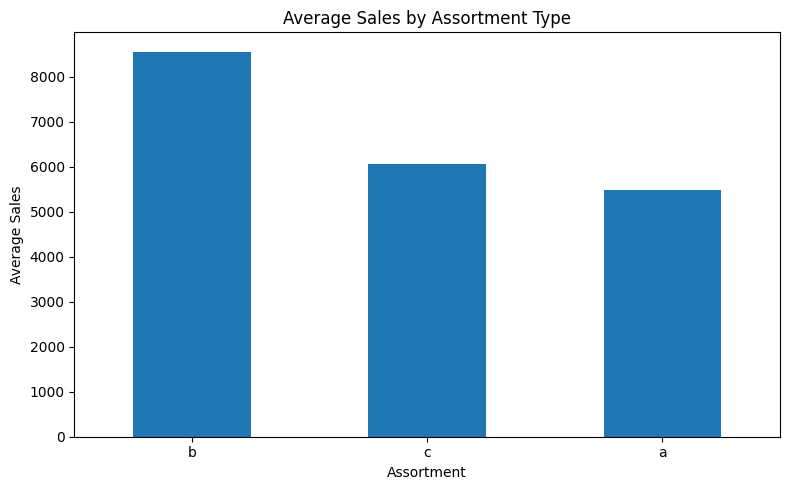

In [ ]:
assortment_sales = train.groupby("Assortment")["Sales"].mean().sort_values(ascending=False)
display(assortment_sales.to_frame("Average Sales"))
assortment_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Average Sales by Assortment Type")
plt.xlabel("Assortment")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 16. Competition Distance Analysis

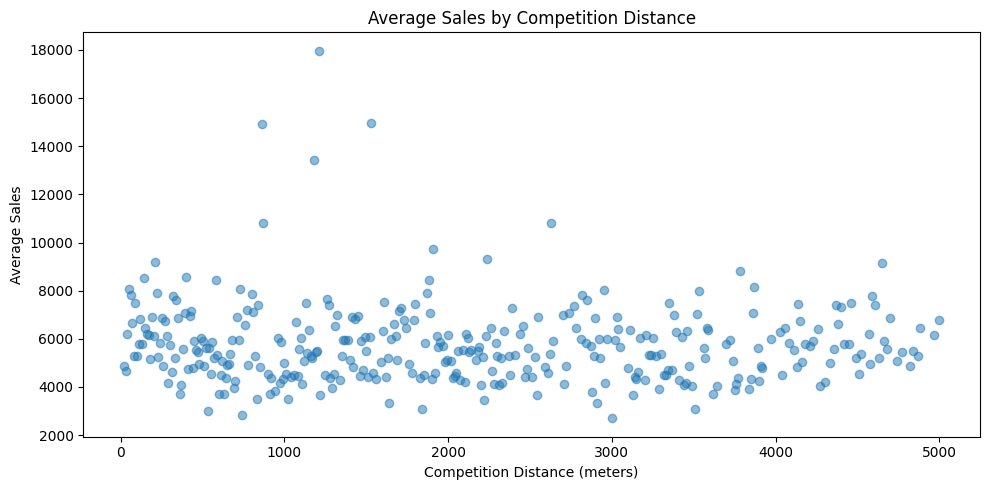

In [ ]:
distance_sales = train.groupby("CompetitionDistance")["Sales"].mean().reset_index()
distance_sales = distance_sales[distance_sales["CompetitionDistance"] <= 5000]
plt.figure(figsize=(10, 5))
plt.scatter(distance_sales["CompetitionDistance"], distance_sales["Sales"], alpha=0.5)
plt.title("Average Sales by Competition Distance")
plt.xlabel("Competition Distance (meters)")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

## 17. Competition Opening / Reopening Analysis

,Average Sales
CompetitorActive,
False,5803.452955
True,5753.971338


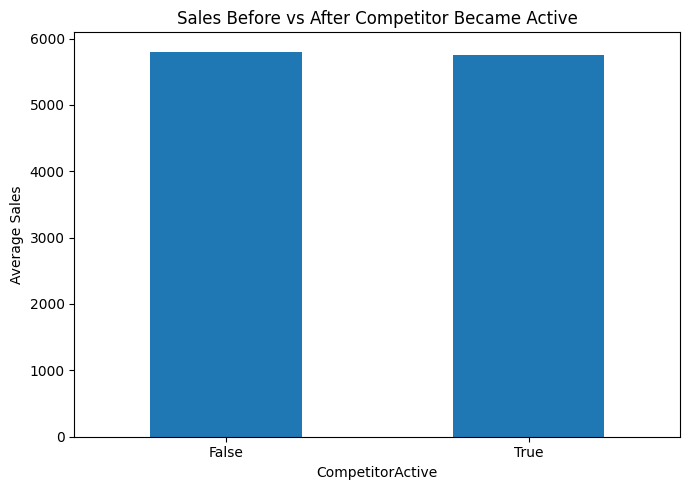

In [ ]:
train["CompetitionOpenSinceYear"] = train["CompetitionOpenSinceYear"].fillna(0)
train["CompetitionOpenSinceMonth"] = train["CompetitionOpenSinceMonth"].fillna(0)

train["CompetitionOpenDate"] = pd.to_datetime(
    train["CompetitionOpenSinceYear"].astype(int).astype(str) + "-" +
    train["CompetitionOpenSinceMonth"].replace(0, 1).astype(int).astype(str) + "-01",
    errors="coerce"
)

train["CompetitorActive"] = train["CompetitionOpenDate"].notna() & (train["Date"] >= train["CompetitionOpenDate"])
competitor_effect = train.groupby("CompetitorActive")["Sales"].mean()
display(competitor_effect.to_frame("Average Sales"))

competitor_effect.plot(kind="bar", figsize=(7, 5))
plt.title("Sales Before vs After Competitor Became Active")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 18. Feature Engineering

In [ ]:
def create_features(df):
    df = df.copy()
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
    df["Day"] = df["Date"].dt.day
    df["DayOfWeek"] = df["Date"].dt.dayofweek + 1
    df["IsWeekend"] = df["DayOfWeek"].isin([6, 7]).astype(int)
    df["DayOfMonthPart"] = pd.cut(df["Day"], bins=[0, 10, 20, 31], labels=["Beginning", "Middle", "End"])
    return df

train = create_features(train)
test = create_features(test)

print("Feature engineering completed.")
display(train[["Date", "Year", "Month", "Week", "Day", "DayOfWeek", "IsWeekend", "DayOfMonthPart"]].head())

Feature engineering completed.


,Date,Year,Month,Week,Day,DayOfWeek,IsWeekend,DayOfMonthPart
0,2015-07-31,2015,7,31,31,5,0,End
1,2015-07-31,2015,7,31,31,5,0,End
2,2015-07-31,2015,7,31,31,5,0,End
3,2015-07-31,2015,7,31,31,5,0,End
4,2015-07-31,2015,7,31,31,5,0,End


## 19. Machine Learning Data and Time-Based Validation

In [ ]:
feature_columns = [
    "Store", "DayOfWeek", "Open", "Promo", "SchoolHoliday",
    "CompetitionDistance", "Promo2", "Year", "Month", "Week", "Day", "IsWeekend"
]

categorical_columns = ["StoreType", "Assortment", "StateHoliday", "DayOfMonthPart"]
numeric_columns = feature_columns

validation_start = train["Date"].max() - pd.Timedelta(days=41)
train_mask = train["Date"] < validation_start
valid_mask = train["Date"] >= validation_start

X_train = train.loc[train_mask, feature_columns + categorical_columns]
X_valid = train.loc[valid_mask, feature_columns + categorical_columns]
y_train = train.loc[train_mask, "Sales"]
y_valid = train.loc[valid_mask, "Sales"]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

Training rows: 970379
Validation rows: 46830


## 20. Scikit-learn Preprocessing Pipeline

The project brief specifically asks for sklearn pipelines. The pipeline keeps preprocessing and modelling together and helps avoid inconsistent transformations.

In [ ]:
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
])

sales_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

sales_pipeline.fit(X_train, y_train)
sales_pred = sales_pipeline.predict(X_valid)

mae = mean_absolute_error(y_valid, sales_pred)
rmse = mean_squared_error(y_valid, sales_pred) ** 0.5

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 922.2
RMSE: 1420.68


## 21. Loss Function / Evaluation

We use **RMSE** as the main loss metric because it is easy to explain and gives larger errors more weight. MAE is also reported because it is directly interpretable as average absolute error.

## 22. Actual vs Predicted Sales

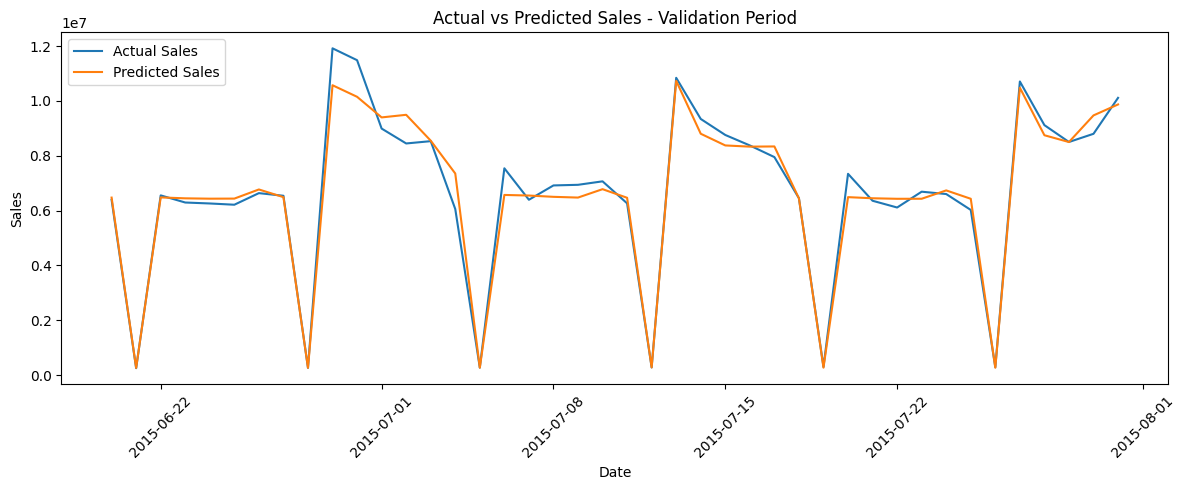

In [ ]:
actual_pred = pd.DataFrame({
    "Date": train.loc[valid_mask, "Date"].values,
    "Actual Sales": y_valid.values,
    "Predicted Sales": sales_pred
})

daily_actual_pred = actual_pred.groupby("Date")[["Actual Sales", "Predicted Sales"]].sum().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(daily_actual_pred["Date"], daily_actual_pred["Actual Sales"], label="Actual Sales")
plt.plot(daily_actual_pred["Date"], daily_actual_pred["Predicted Sales"], label="Predicted Sales")
plt.title("Actual vs Predicted Sales - Validation Period")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 23. Prediction Error Analysis

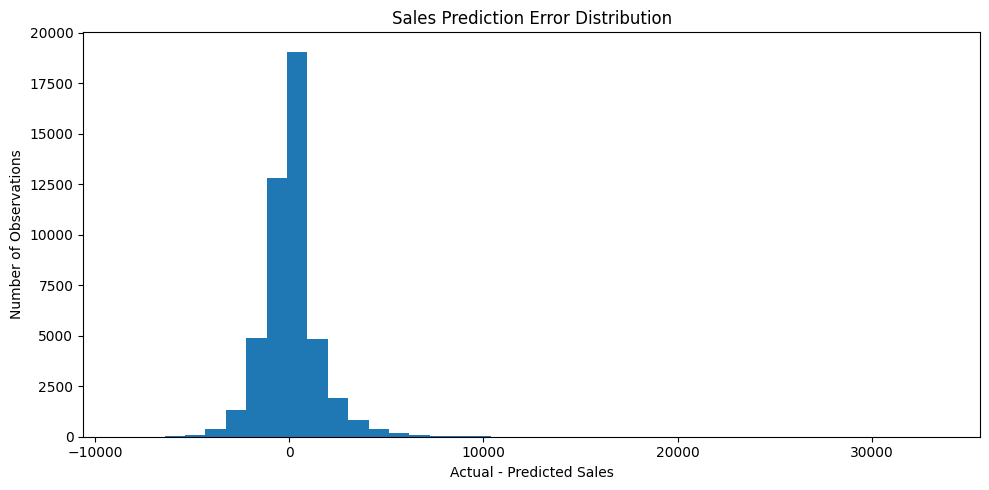

In [ ]:
actual_pred["Error"] = actual_pred["Actual Sales"] - actual_pred["Predicted Sales"]

plt.figure(figsize=(10, 5))
plt.hist(actual_pred["Error"], bins=40)
plt.title("Sales Prediction Error Distribution")
plt.xlabel("Actual - Predicted Sales")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

## 24. Feature Importance

,Feature,Importance
2,numeric__Open,0.534783
5,numeric__CompetitionDistance,0.128375
0,numeric__Store,0.117577
3,numeric__Promo,0.083385
1,numeric__DayOfWeek,0.029298
13,categorical__StoreType_b,0.015621
9,numeric__Week,0.015345
6,numeric__Promo2,0.014017
10,numeric__Day,0.012408
12,categorical__StoreType_a,0.007408


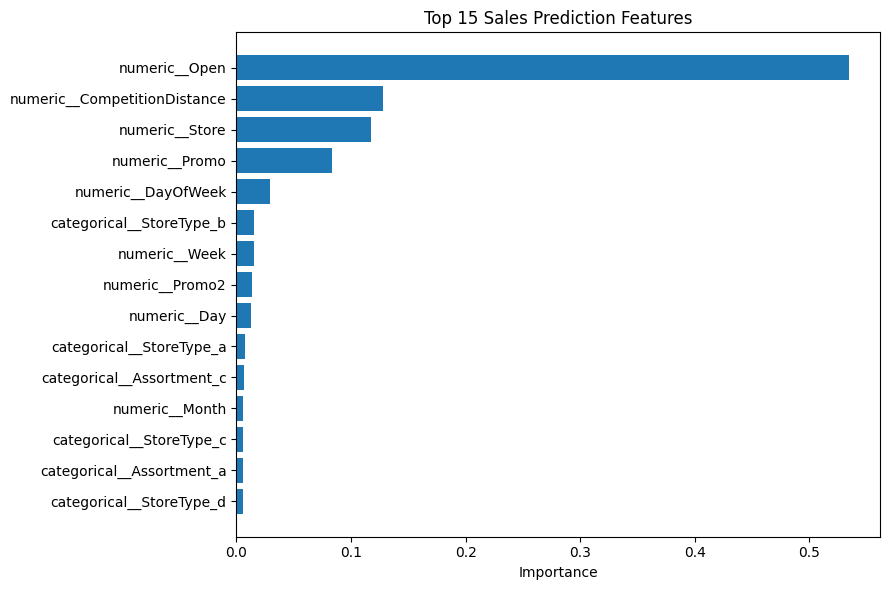

In [ ]:
rf_model = sales_pipeline.named_steps["model"]
encoded_names = sales_pipeline.named_steps["preprocessor"].get_feature_names_out()
importance = pd.DataFrame({"Feature": encoded_names, "Importance": rf_model.feature_importances_})
importance = importance.sort_values("Importance", ascending=False).head(15)
display(importance)

plt.figure(figsize=(9, 6))
plt.barh(importance["Feature"][::-1], importance["Importance"][::-1])
plt.title("Top 15 Sales Prediction Features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 25. Prediction Interval Estimate

The original brief asks for a creative estimate of prediction uncertainty. Here we use the validation residuals to create an **empirical 90% prediction interval**. This is an approximate interval, not a formal statistical confidence interval.

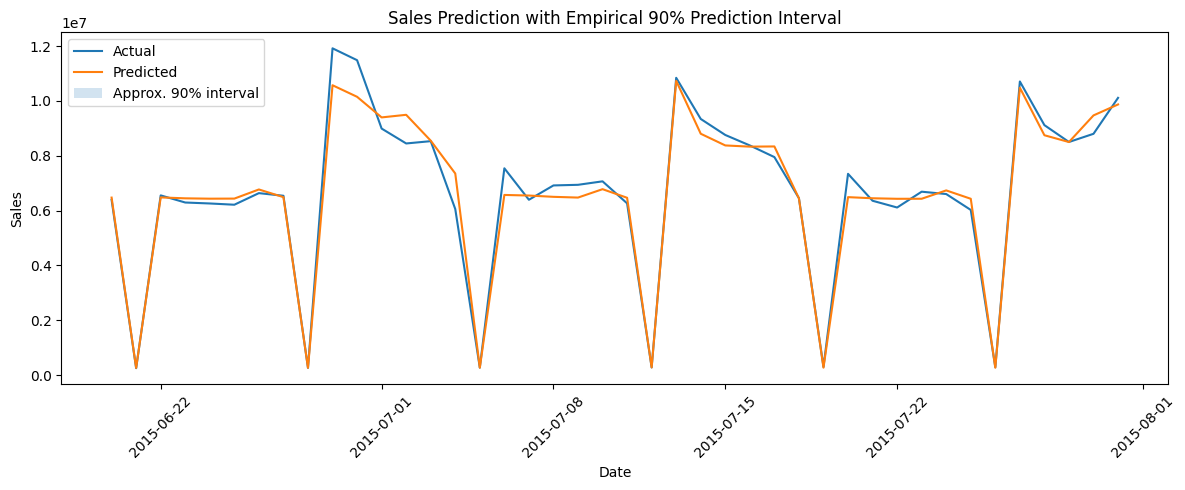

In [ ]:
residuals = y_valid.values - sales_pred
low_error = np.percentile(residuals, 5)
high_error = np.percentile(residuals, 95)

daily_actual_pred["Lower Prediction"] = daily_actual_pred["Predicted Sales"] + low_error
daily_actual_pred["Upper Prediction"] = daily_actual_pred["Predicted Sales"] + high_error

plt.figure(figsize=(12, 5))
plt.plot(daily_actual_pred["Date"], daily_actual_pred["Actual Sales"], label="Actual")
plt.plot(daily_actual_pred["Date"], daily_actual_pred["Predicted Sales"], label="Predicted")
plt.fill_between(daily_actual_pred["Date"], daily_actual_pred["Lower Prediction"], daily_actual_pred["Upper Prediction"], alpha=0.2, label="Approx. 90% interval")
plt.title("Sales Prediction with Empirical 90% Prediction Interval")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 26. Customer Prediction

In [ ]:
customer_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=150, max_depth=18, min_samples_leaf=2, random_state=42, n_jobs=-1
    ))
])

y_customer_train = train.loc[train_mask, "Customers"]
y_customer_valid = train.loc[valid_mask, "Customers"]
customer_pipeline.fit(X_train, y_customer_train)
customer_pred = customer_pipeline.predict(X_valid)

customer_mae = mean_absolute_error(y_customer_valid, customer_pred)
customer_rmse = mean_squared_error(y_customer_valid, customer_pred) ** 0.5
print("Customer MAE:", round(customer_mae, 2))
print("Customer RMSE:", round(customer_rmse, 2))

Customer MAE: 73.06
Customer RMSE: 110.03


## 27. Actual vs Predicted Customers

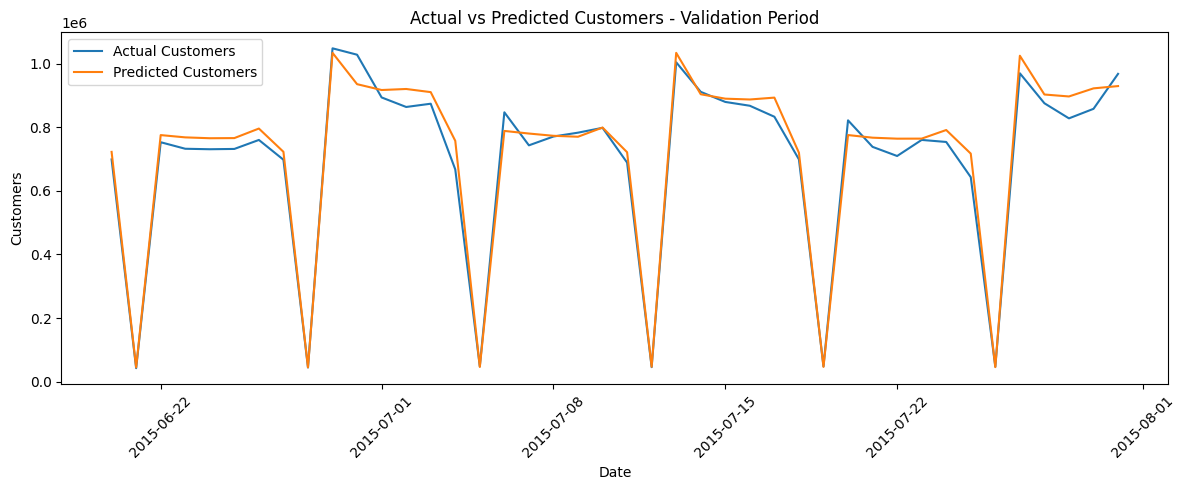

In [ ]:
customer_result = pd.DataFrame({
    "Date": train.loc[valid_mask, "Date"].values,
    "Actual Customers": y_customer_valid.values,
    "Predicted Customers": customer_pred
})

daily_customer = customer_result.groupby("Date")[["Actual Customers", "Predicted Customers"]].sum().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(daily_customer["Date"], daily_customer["Actual Customers"], label="Actual Customers")
plt.plot(daily_customer["Date"], daily_customer["Predicted Customers"], label="Predicted Customers")
plt.title("Actual vs Predicted Customers - Validation Period")
plt.xlabel("Date")
plt.ylabel("Customers")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 28. Time-Series Preparation for LSTM

In [ ]:
daily_series = train.groupby("Date", as_index=False)["Sales"].sum().sort_values("Date")
sales_series = daily_series.set_index("Date")["Sales"]

print("Number of daily observations:", len(sales_series))

adf_result = adfuller(sales_series)
print("ADF p-value:", round(adf_result[1], 4))
if adf_result[1] < 0.05:
    print("The series is stationary at the 5% level.")
else:
    print("The series is not stationary at the 5% level, so differencing is useful.")

Number of daily observations: 942
ADF p-value: 0.0001
The series is stationary at the 5% level.


## 29. Differencing, ACF and PACF

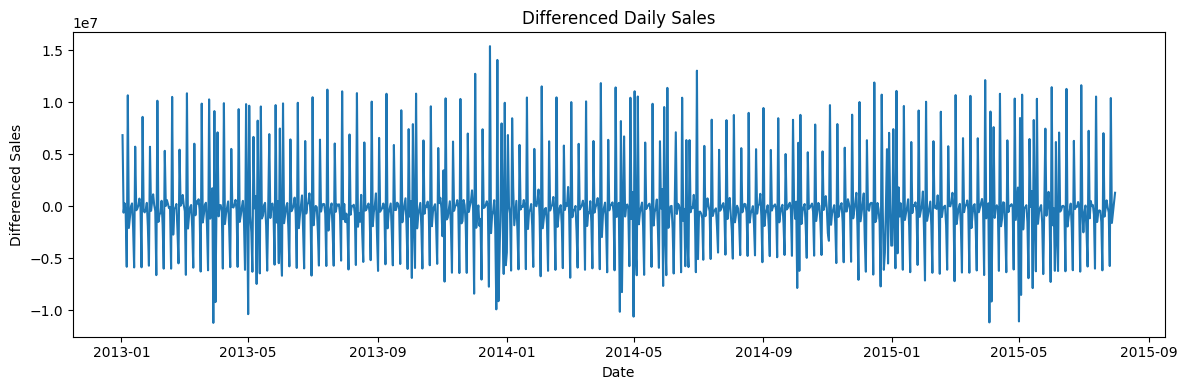

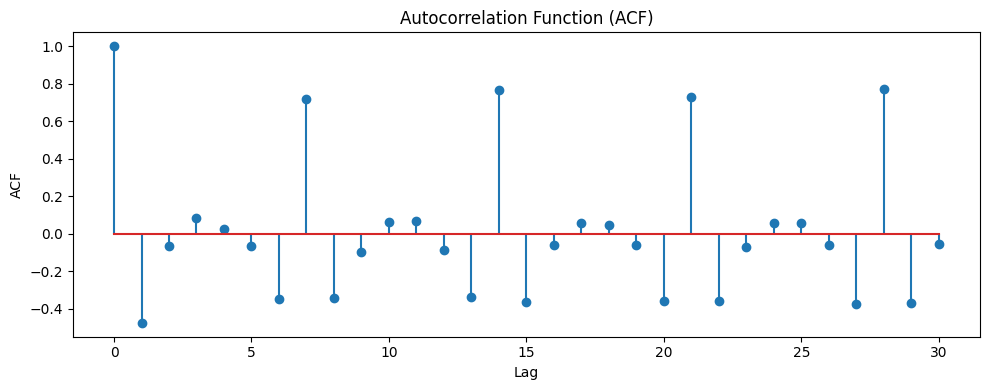

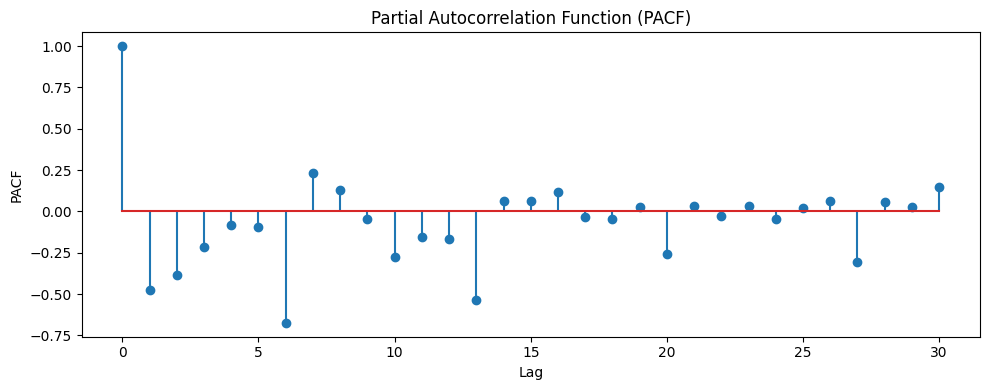

In [ ]:
stationary_series = sales_series.diff().dropna()

plt.figure(figsize=(12, 4))
plt.plot(stationary_series.index, stationary_series.values)
plt.title("Differenced Daily Sales")
plt.xlabel("Date")
plt.ylabel("Differenced Sales")
plt.tight_layout()
plt.show()

acf_values = acf(stationary_series, nlags=30)
pacf_values = pacf(stationary_series, nlags=30)

plt.figure(figsize=(10, 4))
plt.stem(range(len(acf_values)), acf_values)
plt.title("Autocorrelation Function (ACF)")
plt.xlabel("Lag")
plt.ylabel("ACF")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.stem(range(len(pacf_values)), pacf_values)
plt.title("Partial Autocorrelation Function (PACF)")
plt.xlabel("Lag")
plt.ylabel("PACF")
plt.tight_layout()
plt.show()

## 30. Two-Layer LSTM Model

The brief asks for a two-layer LSTM. The scaler is fitted only on the training period to avoid leakage.

In [ ]:
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
    HAS_TENSORFLOW = True
except ImportError:
    HAS_TENSORFLOW = False
    print("TensorFlow is not installed. Install it to run the LSTM section.")

if HAS_TENSORFLOW:
    values = sales_series.values.reshape(-1, 1)
    lstm_split = len(values) - 42
    train_values = values[:lstm_split]
    valid_values = values[lstm_split:]

    lstm_scaler = MinMaxScaler(feature_range=(-1, 1))
    lstm_scaler.fit(train_values)
    train_scaled = lstm_scaler.transform(train_values)
    valid_scaled = lstm_scaler.transform(valid_values)

    def make_sequences(values, window=14):
        X, y = [], []
        for i in range(window, len(values)):
            X.append(values[i-window:i])
            y.append(values[i])
        return np.array(X), np.array(y)

    X_lstm_train, y_lstm_train = make_sequences(train_scaled, 14)
    combined = np.vstack([train_scaled[-14:], valid_scaled])
    X_lstm_valid, y_lstm_valid = make_sequences(combined, 14)

    lstm_model = Sequential([
        LSTM(50, return_sequences=True, input_shape=(14, 1)),
        Dropout(0.2),
        LSTM(50),
        Dropout(0.2),
        Dense(1)
    ])
    lstm_model.compile(optimizer="adam", loss="mse")

    early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    history = lstm_model.fit(
        X_lstm_train, y_lstm_train,
        validation_data=(X_lstm_valid, y_lstm_valid),
        epochs=30, batch_size=32, verbose=1, callbacks=[early_stop]
    )

    lstm_pred = lstm_scaler.inverse_transform(lstm_model.predict(X_lstm_valid, verbose=0)).ravel()
    lstm_actual = lstm_scaler.inverse_transform(y_lstm_valid).ravel()
    lstm_rmse = mean_squared_error(lstm_actual, lstm_pred) ** 0.5
    print("LSTM RMSE:", round(lstm_rmse, 2))

Epoch 1/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - loss: 0.1710 - val_loss: 0.1539
Epoch 2/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.1621 - val_loss: 0.1459
Epoch 3/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.1557 - val_loss: 0.1277
Epoch 4/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.1410 - val_loss: 0.0998
Epoch 5/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1308 - val_loss: 0.0781
Epoch 6/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1171 - val_loss: 0.0672
Epoch 7/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1136 - val_loss: 0.0590
Epoch 8/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.1134 - val_loss: 0.0580
Epoch 9/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.1043 - val_loss: 0.0497
Epoch 10/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.1033 - val_loss: 0.0662
Epoch 11/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0950 - val_loss: 0.0517
Epoch 12/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0

## 31. LSTM Training Curve

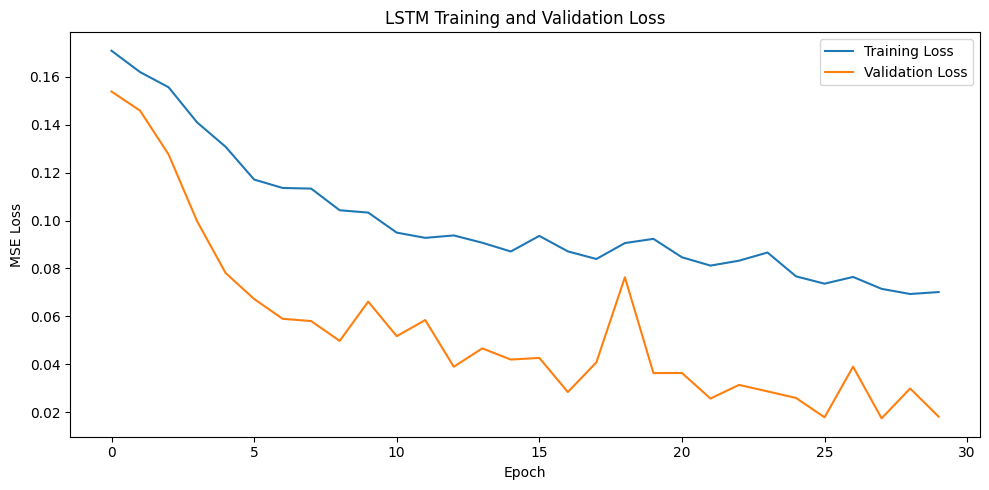

In [ ]:
if HAS_TENSORFLOW:
    plt.figure(figsize=(10, 5))
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title("LSTM Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 32. Random Forest vs LSTM Model Comparison

,Model,RMSE
0,Random Forest,1.420675e+03
1,LSTM,1.023666e+06


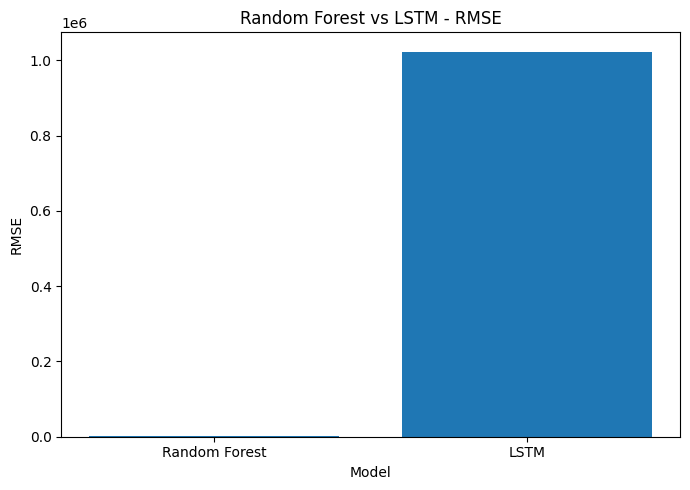

In [ ]:
models = {"Random Forest": rmse}
if HAS_TENSORFLOW:
    models["LSTM"] = lstm_rmse
comparison = pd.DataFrame(list(models.items()), columns=["Model", "RMSE"])
display(comparison)

plt.figure(figsize=(7, 5))
plt.bar(comparison["Model"], comparison["RMSE"])
plt.title("Random Forest vs LSTM - RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.tight_layout()
plt.show()

## 33. MLflow Experiment Tracking

Run this section when MLflow is installed. Multiple model configurations are logged so model versions can be compared.

In [7]:
!pip install mlflow -q
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import mlflow

# Imports for ColumnTransformer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Load the Rossmann Data (from cell 01d3fc57)
train = pd.read_csv("/train.csv", dtype={'StateHoliday': str})
test = pd.read_csv("/test.csv", dtype={'StateHoliday': str})
store = pd.read_csv("/store.csv")

train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])

# Merge Store Information and Data Cleaning (from cell 12687579)
train = train.merge(store, on="Store", how="left")
test = test.merge(store, on="Store", how="left")

median_distance = train["CompetitionDistance"].median()
train["CompetitionDistance"] = train["CompetitionDistance"].fillna(median_distance)
test["CompetitionDistance"] = test["CompetitionDistance"].fillna(median_distance)

train["StateHoliday"] = train["StateHoliday"].astype(str)
test["StateHoliday"] = test["StateHoliday"].astype(str)

# Feature Engineering (from cell 58dcb3dd)
def create_features(df):
    df = df.copy()
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
    df["Day"] = df["Date"].dt.day
    df["DayOfWeek"] = df["Date"].dt.dayofweek + 1
    df["IsWeekend"] = df["DayOfWeek"].isin([6, 7]).astype(int)
    df["DayOfMonthPart"] = pd.cut(df["Day"], bins=[0, 10, 20, 31], labels=["Beginning", "Middle", "End"])
    return df

train = create_features(train)
test = create_features(test)

# Definitions for preprocessor
feature_columns = [
    "Store", "DayOfWeek", "Open", "Promo", "SchoolHoliday",
    "CompetitionDistance", "Promo2", "Year", "Month", "Week", "Day", "IsWeekend"
]

categorical_columns = ["StoreType", "Assortment", "StateHoliday", "DayOfMonthPart"]
numeric_columns = [col for col in feature_columns if col not in categorical_columns] # Adjusted for numeric in preprocessor

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
])

# Define training and validation sets
validation_start = train["Date"].max() - pd.Timedelta(days=41)
train_mask = train["Date"] < validation_start
valid_mask = train["Date"] >= validation_start

X_train = train.loc[train_mask, feature_columns + categorical_columns]
X_valid = train.loc[valid_mask, feature_columns + categorical_columns]
y_train = train.loc[train_mask, "Sales"]
y_valid = train.loc[valid_mask, "Sales"]

mlflow.set_experiment("Rossmann Sales Forecasting")

results = []

for trees in [100, 150, 200]:

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=trees,
            max_depth=18,
            random_state=42,
            n_jobs=-1
        ))
    ])

    with mlflow.start_run(run_name=f"RF_{trees}"):

        # Train
        model.fit(X_train, y_train)

        # Predict
        prediction = model.predict(X_valid)

        # Metrics
        mae = mean_absolute_error(y_valid, prediction)
        rmse = np.sqrt(mean_squared_error(y_valid, prediction))

        # Log parameters
        mlflow.log_param("model", "Random Forest")
        mlflow.log_param("n_estimators", trees)
        mlflow.log_param("max_depth", 18)

        # Log metrics
        mlflow.log_metric("MAE", mae)
        mlflow.log_metric("RMSE", rmse)

        # Save model in MLflow
        mlflow.sklearn.log_model(model, "model", skops_trusted_types=["sklearn.compose._column_transformer._RemainderColsList"])

        results.append([trees, mae, rmse])

        print("Trees:", trees)
        print("MAE:", round(mae, 2))
        print("RMSE:", round(rmse, 2))
        print("----------------------")

results_df = pd.DataFrame(
    results,
    columns=["Trees", "MAE", "RMSE"]
)

results_df.sort_values("RMSE")

/tmp/ipykernel_888/2894250624.py:14: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("/train.csv")
2026/09/15 17:48:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Trees: 100
MAE: 924.72
RMSE: 1423.11
----------------------


2026/09/15 18:00:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Trees: 150
MAE: 923.15
RMSE: 1421.66
----------------------


2026/09/15 18:16:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Trees: 200
MAE: 921.28
RMSE: 1418.8
----------------------


,Trees,MAE,RMSE
2,200,921.280532,1418.799005
1,150,923.154681,1421.662677
0,100,924.718363,1423.111897


## 34. Train Final Models on All Training Data

In [ ]:
X_all = train[feature_columns + categorical_columns]
X_test = test[feature_columns + categorical_columns]
y_sales_all = train["Sales"]
y_customers_all = train["Customers"]

final_sales_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=150, max_depth=18, min_samples_leaf=2, random_state=42, n_jobs=-1))
])
final_customer_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=150, max_depth=18, min_samples_leaf=2, random_state=42, n_jobs=-1))
])

final_sales_model.fit(X_all, y_sales_all)
final_customer_model.fit(X_all, y_customers_all)
print("Final models trained.")

Final models trained.


## 35. 42-Day / 6-Week Sales Forecast

In [ ]:
forecast_dates = sorted(test["Date"].unique())[:42]
forecast_mask = test["Date"].isin(forecast_dates)
X_forecast = test.loc[forecast_mask, feature_columns + categorical_columns]

predicted_sales = final_sales_model.predict(X_forecast)
predicted_customers = final_customer_model.predict(X_forecast)

forecast = test.loc[forecast_mask, ["Date"]].copy()
forecast["Predicted Sales"] = predicted_sales
forecast["Predicted Customers"] = predicted_customers

daily_forecast = forecast.groupby("Date")[["Predicted Sales", "Predicted Customers"]].sum().reset_index()
print("Forecast days:", len(daily_forecast))
display(daily_forecast.head())

Forecast days: 42


,Date,Predicted Sales,Predicted Customers
0,2015-08-01,5.243362e+06,574743.952929
1,2015-08-02,2.346421e+05,39819.898097
2,2015-08-03,8.212344e+06,777230.871012
3,2015-08-04,6.669351e+06,676989.345595
4,2015-08-05,6.421052e+06,667504.811244


## 36. 42-Day Forecast Chart

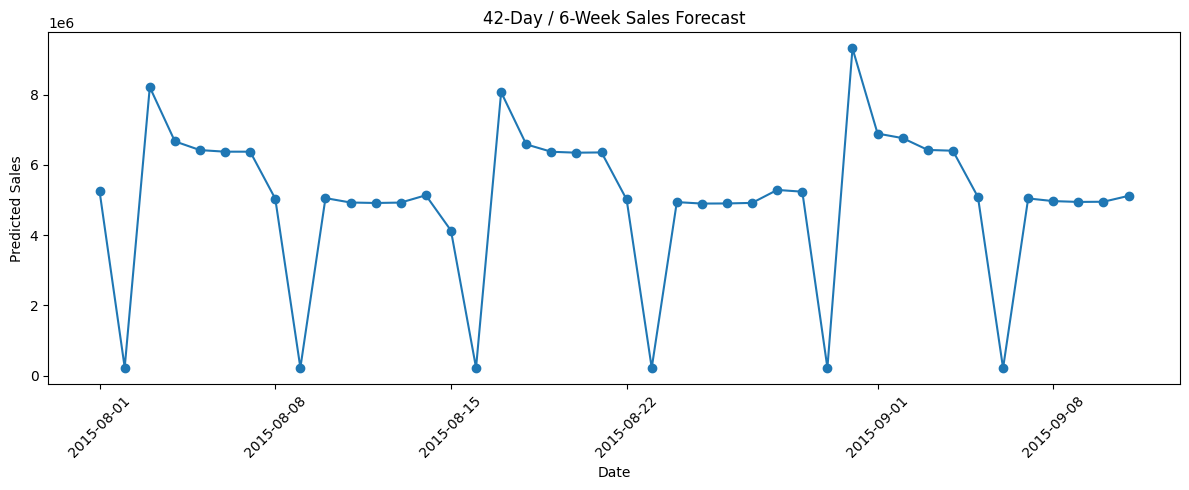

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(daily_forecast["Date"], daily_forecast["Predicted Sales"], marker="o")
plt.title("42-Day / 6-Week Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 37. Daily 42-Day Forecast: Sales and Customers

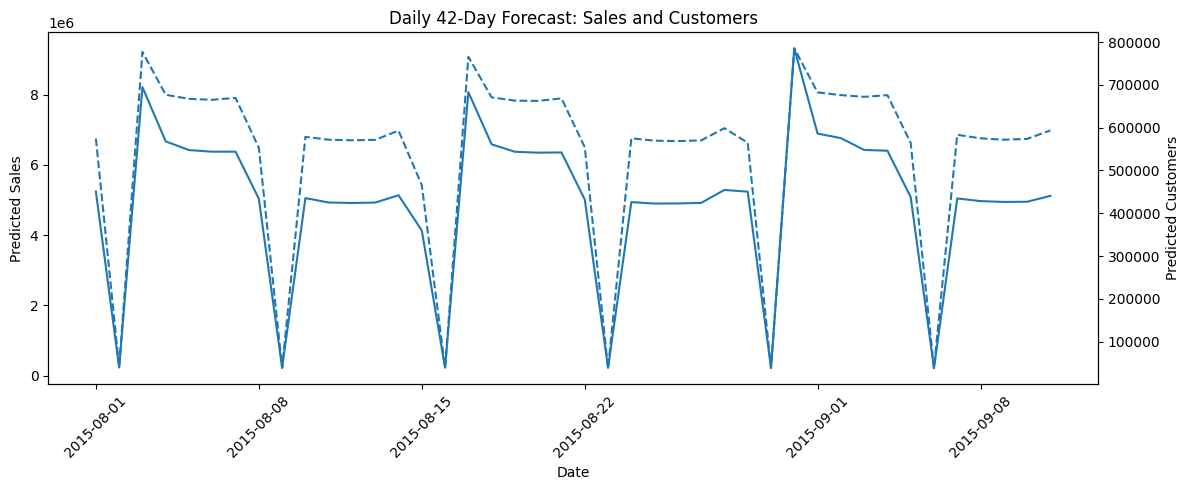

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(daily_forecast["Date"], daily_forecast["Predicted Sales"], label="Predicted Sales")
ax1.set_xlabel("Date")
ax1.set_ylabel("Predicted Sales")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(daily_forecast["Date"], daily_forecast["Predicted Customers"], label="Predicted Customers", linestyle="--")
ax2.set_ylabel("Predicted Customers")
plt.title("Daily 42-Day Forecast: Sales and Customers")
plt.tight_layout()
plt.show()

## 38. Save Forecast Results

In [ ]:
daily_forecast.to_csv("rossmann_42_day_forecast.csv", index=False)
print("Saved rossmann_42_day_forecast.csv")

Saved rossmann_42_day_forecast.csv


## 39. Timestamped Model Serialization

In [ ]:
timestamp = datetime.now().strftime("%d-%m-%Y-%H-%M-%S")
model_file = f"rossmann_sales_model_{timestamp}.pkl"
customer_model_file = f"rossmann_customer_model_{timestamp}.pkl"

import joblib
joblib.dump(final_sales_model, model_file)
joblib.dump(final_customer_model, customer_model_file)
joblib.dump(feature_columns + categorical_columns, "rossmann_model_columns.pkl")

print("Saved:", model_file)
print("Saved:", customer_model_file)

Saved: rossmann_sales_model_14-09-2026-10-44-03.pkl
Saved: rossmann_customer_model_14-09-2026-10-44-03.pkl


## 40. DVC Versioning Checklist

The brief asks for screenshots showing multiple data versions in DVC. Run these commands in the project terminal after installing DVC:

```bash
dvc init
dvc add data/train.csv data/test.csv data/store.csv
git add data/*.dvc .dvc
git commit -m "Add Rossmann dataset version 1"

# After changing/updating the dataset
dvc add data/train.csv data/test.csv data/store.csv
git add data/*.dvc
git commit -m "Add Rossmann dataset version 2"
```

Then take a screenshot of the Git/DVC history as evidence. Do not claim multiple DVC versions unless they were actually created.

## 41. Web Deployment Preparation

The notebook saves the trained model and forecast CSV. The Flask application should load the serialized model and accept the manager's inputs. The original brief requires the web interface to output **predicted sales and customer numbers**, show a plot, and allow the user to download predictions as CSV.

Recommended deployment flow:

`Notebook → Train → Serialize model → Flask app → HTML dashboard → Cloud hosting`

The deployment platform can be Heroku or another hosting platform that supports Flask.

## 42. Business Recommendations

1. Use the 6-week forecast for inventory and staffing planning.
2. Prioritize promotions for stores with strong measured promotion lift.
3. Adjust staffing using weekday and weekend demand patterns.
4. Monitor stores affected by competitor openings.
5. Use predicted customer numbers together with predicted sales to plan store capacity and stock.

These recommendations should be refined using the actual model results.